# Training Pipeline — BEED EEG Epileptic Seizure Detection (Dataset 5)

Training **9 classical ML models + 1 Stacking Ensemble** with **Stratified K-Fold Cross Validation** on the preprocessed BEED EEG dataset.

| # | Model |
|---|---|
| 1 | Logistic Regression |
| 2 | Decision Tree |
| 3 | K-Nearest Neighbors (KNN) |
| 4 | Random Forest |
| 5 | Support Vector Machine (SVM) |
| 6 | XGBoost |
| 7 | AdaBoost |
| 8 | Gradient Boosting |
| 9 | LightGBM |
| 10 | **Stacking Ensemble** (RF + Extra Trees + XGBoost → CatBoost) |

**Task:** 4-class classification (Healthy / Generalized Seizure / Focal Seizure / Seizure Events)  
**Evaluation:** Stratified 5-Fold CV on train set + Final evaluation on held-out test set

## Import Libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
import time

# Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier
)
from sklearn.svm import SVC
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Cross Validation & Metrics
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)

warnings.filterwarnings('ignore')
sns.set_style("whitegrid")
plt.rcParams['figure.dpi'] = 100

print("All libraries imported successfully")

All libraries imported successfully


## Load Preprocessed Datasets

Loading the preprocessed BEED EEG train and test sets (already normalized, 4-class labels).

In [2]:
# Load preprocessed train and test sets
train_df = pd.read_csv('/kaggle/input/datasets/mosharafapurbo/dataset-5-preprocessed-beed/5_BEED_train.csv')
test_df = pd.read_csv('/kaggle/input/datasets/mosharafapurbo/dataset-5-preprocessed-beed/5_BEED_test.csv')

LABEL = 'y'

X_train = train_df.drop(columns=[LABEL]).values
y_train = train_df[LABEL].astype(int).values
X_test = test_df.drop(columns=[LABEL]).values
y_test = test_df[LABEL].astype(int).values

CLASS_NAMES = ['Healthy', 'Generalized', 'Focal', 'Seizure Events']

print(f"Train: {X_train.shape}  |  Test: {X_test.shape}")
print(f"Features: {train_df.drop(columns=[LABEL]).columns.tolist()}")
print(f"\nTrain class distribution:")
for cls, name in enumerate(CLASS_NAMES):
    count = np.sum(y_train == cls)
    print(f"  {cls} ({name}): {count} ({count/len(y_train)*100:.1f}%)")
print(f"\nTest class distribution:")
for cls, name in enumerate(CLASS_NAMES):
    count = np.sum(y_test == cls)
    print(f"  {cls} ({name}): {count} ({count/len(y_test)*100:.1f}%)")

Train: (6400, 16)  |  Test: (1600, 16)
Features: ['X1', 'X2', 'X3', 'X4', 'X5', 'X6', 'X7', 'X8', 'X9', 'X10', 'X11', 'X12', 'X13', 'X14', 'X15', 'X16']

Train class distribution:
  0 (Healthy): 1600 (25.0%)
  1 (Generalized): 1600 (25.0%)
  2 (Focal): 1600 (25.0%)
  3 (Seizure Events): 1600 (25.0%)

Test class distribution:
  0 (Healthy): 400 (25.0%)
  1 (Generalized): 400 (25.0%)
  2 (Focal): 400 (25.0%)
  3 (Seizure Events): 400 (25.0%)


## Setup: K-Fold Cross Validation & Helper Functions

Using **Stratified 5-Fold CV** on the training set to get reliable accuracy estimates, then evaluating on the held-out test set for final performance.

In [3]:
# Stratified K-Fold setup
N_FOLDS = 5
skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=42)

# Store all results
results = {}

def train_and_evaluate(model, model_name):
    """
    1. Run Stratified 5-Fold CV on training set
    2. Train on full training set
    3. Evaluate on held-out test set
    4. Print results and show confusion matrix
    """
    # ── K-Fold Cross Validation on train set ──
    cv_scores = cross_val_score(model, X_train, y_train, cv=skf, scoring='accuracy', n_jobs=-1)
    
    # ── Train on full training set ──
    start = time.time()
    model.fit(X_train, y_train)
    train_time = time.time() - start
    
    # ── Evaluate on test set ──
    y_pred = model.predict(X_test)
    test_acc = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    
    # ── Store results ──
    results[model_name] = {
        'model': model,
        'cv_scores': cv_scores,
        'cv_mean': cv_scores.mean(),
        'cv_std': cv_scores.std(),
        'test_accuracy': test_acc,
        'confusion_matrix': cm,
        'predictions': y_pred,
        'train_time': train_time
    }
    
    # ── Print results ──
    print(f"{'=' * 60}")
    print(f"  {model_name}")
    print(f"{'=' * 60}")
    print(f"  K-Fold CV Accuracy:  {cv_scores.mean():.4f} +/- {cv_scores.std():.4f}")
    print(f"  Fold scores:         {[f'{s:.4f}' for s in cv_scores]}")
    print(f"  Test Set Accuracy:   {test_acc:.4f}  ({test_acc*100:.2f}%)")
    print(f"  Train Time:          {train_time:.2f}s")
    print(f"{'=' * 60}\n")
    
    # ── Confusion Matrix ──
    fig, ax = plt.subplots(1, 1, figsize=(7, 6))
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=CLASS_NAMES)
    disp.plot(ax=ax, cmap='Blues', values_format='d')
    ax.set_title(f'{model_name}\nTest Acc: {test_acc*100:.2f}%  |  CV: {cv_scores.mean()*100:.2f}%',
                 fontsize=13, fontweight='bold')
    plt.xticks(rotation=20, ha='right')
    plt.tight_layout()
    plt.show()
    
    return test_acc

print(f"Stratified {N_FOLDS}-Fold CV configured")
print("Helper function defined")

Stratified 5-Fold CV configured
Helper function defined


---
## Model Training

### 1. Logistic Regression

  Logistic Regression
  K-Fold CV Accuracy:  0.4723 +/- 0.0086
  Fold scores:         ['0.4672', '0.4734', '0.4844', '0.4773', '0.4594']
  Test Set Accuracy:   0.4544  (45.44%)
  Train Time:          0.16s



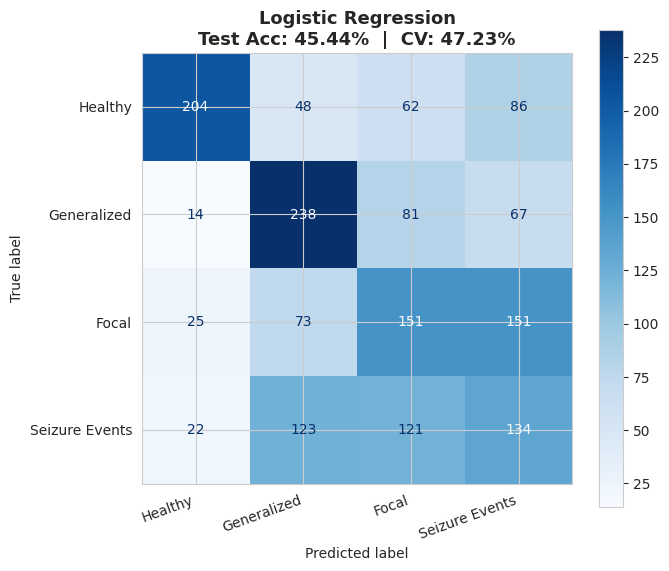

0.454375

In [4]:
# 1. Logistic Regression
lr_model = LogisticRegression(max_iter=1000, random_state=42, solver='lbfgs')
train_and_evaluate(lr_model, "Logistic Regression")

### 2. Decision Tree

  Decision Tree
  K-Fold CV Accuracy:  0.8602 +/- 0.0094
  Fold scores:         ['0.8477', '0.8516', '0.8609', '0.8711', '0.8695']
  Test Set Accuracy:   0.8762  (87.62%)
  Train Time:          0.07s



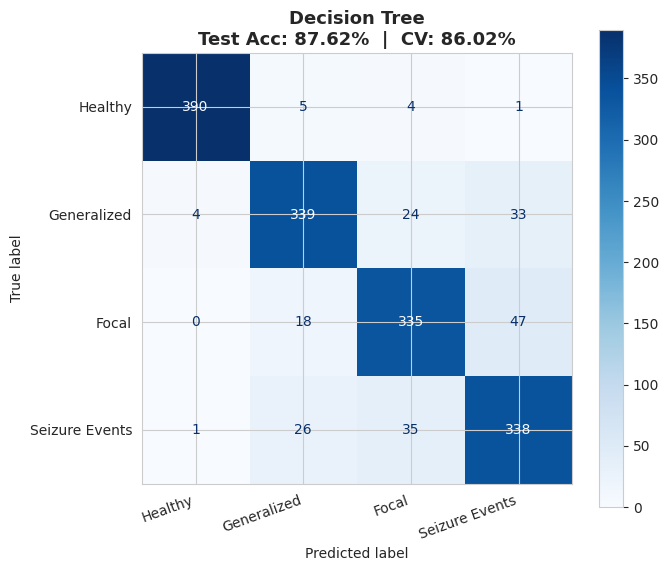

0.87625

In [5]:
# 2. Decision Tree
dt_model = DecisionTreeClassifier(random_state=42)
train_and_evaluate(dt_model, "Decision Tree")

### 3. K-Nearest Neighbors (KNN)

  KNN
  K-Fold CV Accuracy:  0.9430 +/- 0.0039
  Fold scores:         ['0.9414', '0.9359', '0.9461', '0.9453', '0.9461']
  Test Set Accuracy:   0.9706  (97.06%)
  Train Time:          0.00s



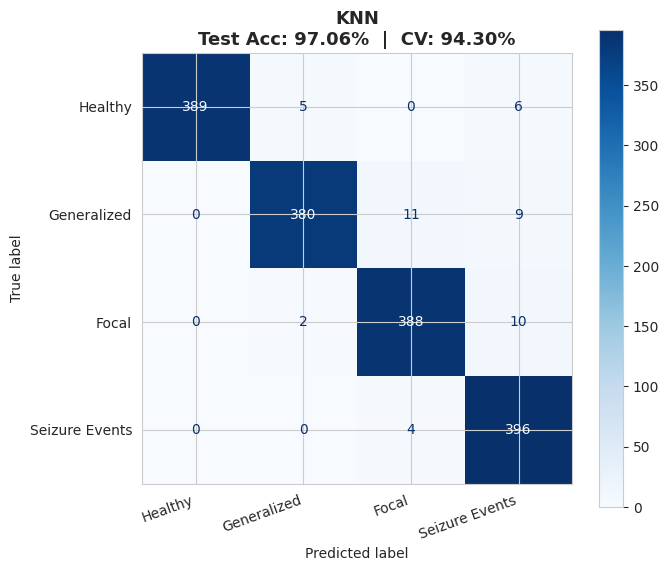

0.970625

In [6]:
# 3. KNN
knn_model = KNeighborsClassifier(n_neighbors=5)
train_and_evaluate(knn_model, "KNN")

### 4. Random Forest

  Random Forest
  K-Fold CV Accuracy:  0.9556 +/- 0.0091
  Fold scores:         ['0.9453', '0.9461', '0.9672', '0.9547', '0.9648']
  Test Set Accuracy:   0.9613  (96.12%)
  Train Time:          0.66s



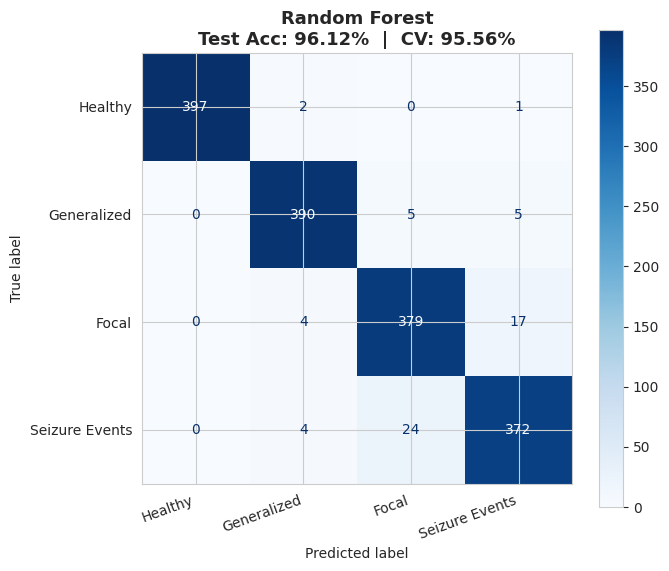

0.96125

In [7]:
# 4. Random Forest
rf_model = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
train_and_evaluate(rf_model, "Random Forest")

### 5. Support Vector Machine (SVM)

  SVM
  K-Fold CV Accuracy:  0.7447 +/- 0.0087
  Fold scores:         ['0.7430', '0.7375', '0.7500', '0.7586', '0.7344']
  Test Set Accuracy:   0.7444  (74.44%)
  Train Time:          0.88s



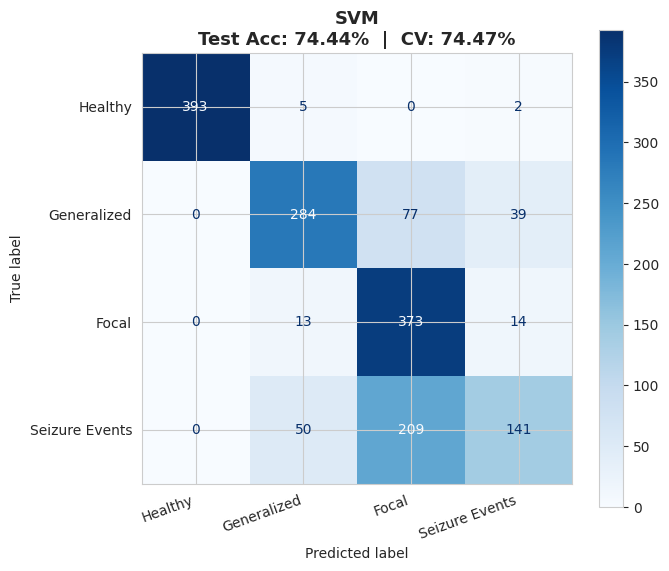

0.744375

In [8]:
# 5. SVM
svm_model = SVC(kernel='rbf', random_state=42)
train_and_evaluate(svm_model, "SVM")

---
## Boosting Models

### 6. XGBoost

  XGBoost
  K-Fold CV Accuracy:  0.9322 +/- 0.0061
  Fold scores:         ['0.9258', '0.9242', '0.9398', '0.9359', '0.9352']
  Test Set Accuracy:   0.9331  (93.31%)
  Train Time:          0.71s



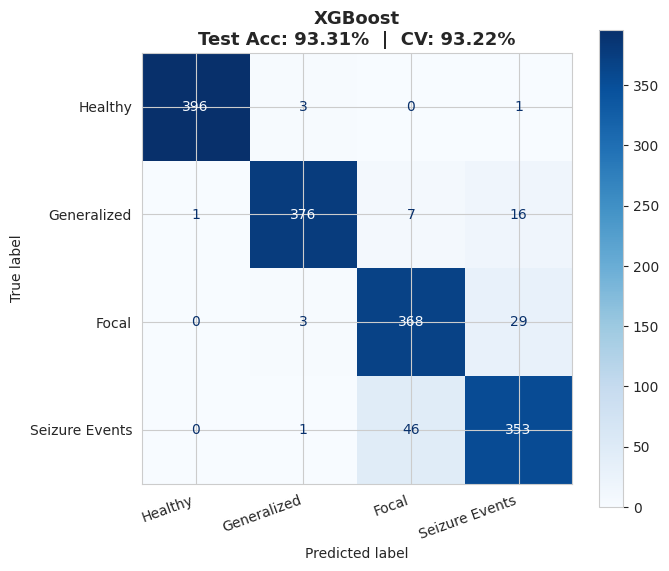

0.933125

In [9]:
# 6. XGBoost
xgb_model = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    use_label_encoder=False,
    eval_metric='mlogloss',
    verbosity=0
)
train_and_evaluate(xgb_model, "XGBoost")

### 7. AdaBoost

  AdaBoost
  K-Fold CV Accuracy:  0.6330 +/- 0.0305
  Fold scores:         ['0.6070', '0.6109', '0.6695', '0.6711', '0.6062']
  Test Set Accuracy:   0.6044  (60.44%)
  Train Time:          0.72s



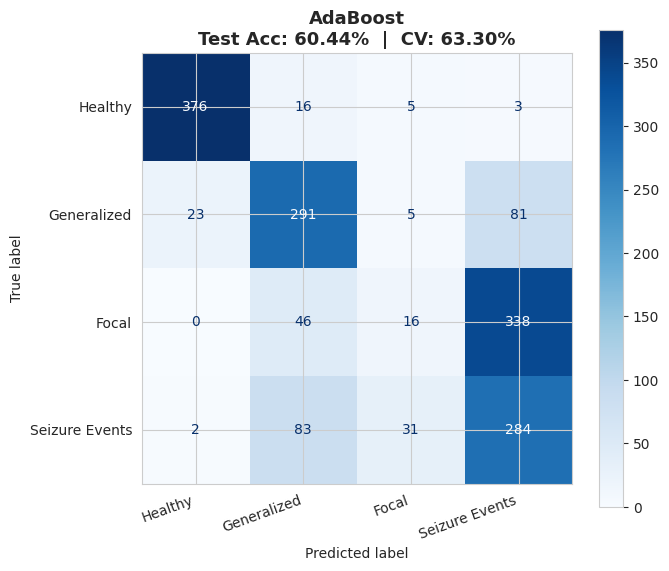

0.604375

In [10]:
# 7. AdaBoost
ada_model = AdaBoostClassifier(n_estimators=100, learning_rate=1.0, random_state=42)
train_and_evaluate(ada_model, "AdaBoost")

### 8. Gradient Boosting

  Gradient Boost
  K-Fold CV Accuracy:  0.8838 +/- 0.0064
  Fold scores:         ['0.8734', '0.8812', '0.8883', '0.8836', '0.8922']
  Test Set Accuracy:   0.8838  (88.38%)
  Train Time:          6.70s



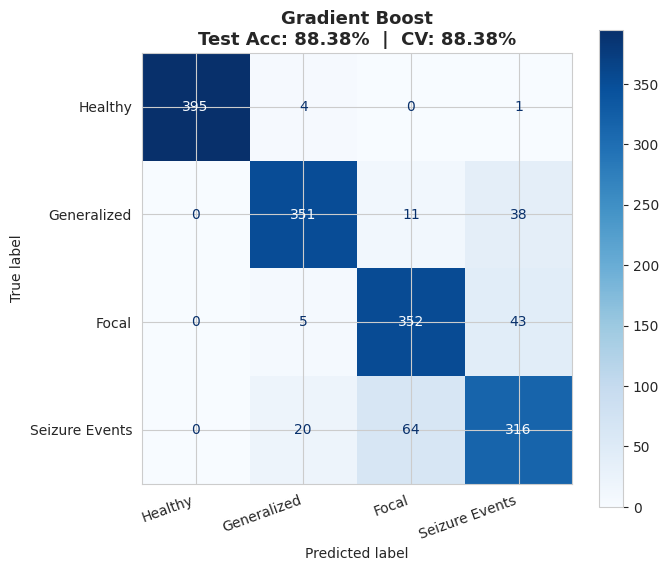

0.88375

In [11]:
# 8. Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)
train_and_evaluate(gb_model, "Gradient Boost")

### 9. LightGBM

/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  LGBM
  K-Fold CV Accuracy:  0.9597 +/- 0.0050
  Fold scores:         ['0.9563', '0.9578', '0.9625', '0.9539', '0.9680']
  Test Set Accuracy:   0.9725  (97.25%)
  Train Time:          0.55s



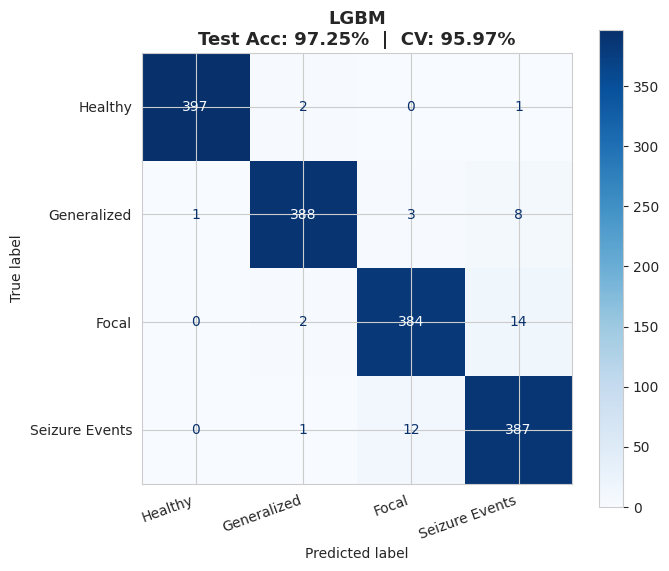

0.9725

In [12]:
# 9. LightGBM
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    num_leaves=31,
    random_state=42,
    verbose=-1,
    verbosity=-1
)
train_and_evaluate(lgbm_model, "LGBM")

---
## Stacking Ensemble

### 10. Two-Level Stacking Ensemble

**Architecture (from the reference paper):**
- **Level 1 (Base Learners):** Random Forest, Extra Trees, XGBoost — trained independently, their predictions form new features
- **Level 2 (Meta-Learner):** CatBoost — learns how to optimally combine Level 1 predictions

This approach achieved **97.06% accuracy** in the reference paper.

/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:151: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:151: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:151: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
/usr/local/lib/python3.12/dist-packages/sklearn/preprocessing/_label.py:151: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,

  Stacking Ensemble
  K-Fold CV Accuracy:  0.9764 +/- 0.0049
  Fold scores:         ['0.9750', '0.9703', '0.9844', '0.9734', '0.9789']
  Test Set Accuracy:   0.9888  (98.88%)
  Train Time:          9.62s



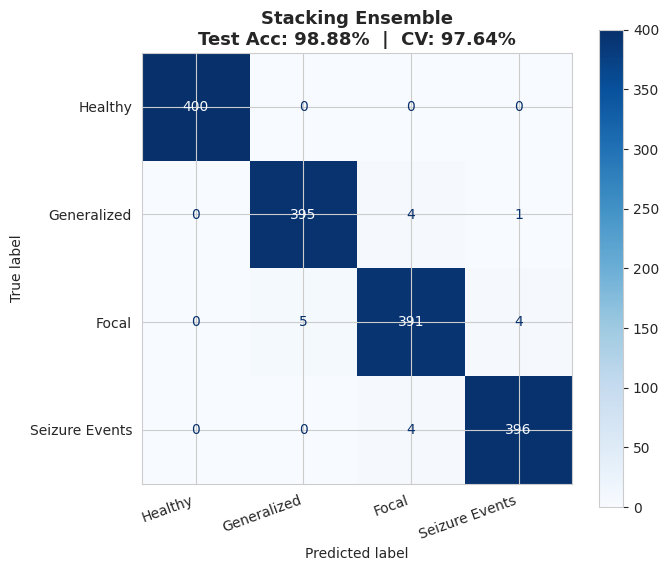

0.98875

In [13]:
from sklearn.ensemble import ExtraTreesClassifier, StackingClassifier
from catboost import CatBoostClassifier

# Level 1: Base Learners
base_learners = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ('et', ExtraTreesClassifier(n_estimators=100, random_state=42, n_jobs=-1)),
    ('xgb', XGBClassifier(
        n_estimators=100, learning_rate=0.1, max_depth=6,
        random_state=42, use_label_encoder=False,
        eval_metric='mlogloss', verbosity=0
    ))
]

# Level 2: Meta-Learner
meta_learner = CatBoostClassifier(
    iterations=100,
    learning_rate=0.1,
    depth=6,
    random_state=42,
    verbose=0
)

# Stacking Ensemble
stacking_model = StackingClassifier(
    estimators=base_learners,
    final_estimator=meta_learner,
    cv=5,
    n_jobs=-1,
    passthrough=False  # only Level 1 predictions go to meta-learner
)

train_and_evaluate(stacking_model, "Stacking Ensemble")

---
## Model Comparison — Accuracy Summary (CV + Test)

In [14]:
# ── Comparison Table ──
comparison_df = pd.DataFrame({
    'Model': list(results.keys()),
    'CV Accuracy (%)': [r['cv_mean'] * 100 for r in results.values()],
    'CV Std (%)': [r['cv_std'] * 100 for r in results.values()],
    'Test Accuracy (%)': [r['test_accuracy'] * 100 for r in results.values()],
    'Train Time (s)': [r['train_time'] for r in results.values()]
}).sort_values('Test Accuracy (%)', ascending=False).reset_index(drop=True)

comparison_df.index += 1
comparison_df.index.name = 'Rank'

print("=" * 75)
print("  MODEL COMPARISON — BEED EEG Seizure Detection (4-Class)")
print("  Stratified 5-Fold CV + Held-Out Test Set")
print("=" * 75)
print(comparison_df.to_string())
print("=" * 75)
best = comparison_df.iloc[0]
print(f"\nBest Model: {best['Model']} — Test: {best['Test Accuracy (%)']:.2f}%  |  CV: {best['CV Accuracy (%)']:.2f}%")
comparison_df

  MODEL COMPARISON — BEED EEG Seizure Detection (4-Class)
  Stratified 5-Fold CV + Held-Out Test Set
                    Model  CV Accuracy (%)  CV Std (%)  Test Accuracy (%)  Train Time (s)
Rank                                                                                     
1       Stacking Ensemble        97.640625    0.485130            98.8750        9.622645
2                    LGBM        95.968750    0.500488            97.2500        0.548167
3                     KNN        94.296875    0.392184            97.0625        0.001186
4           Random Forest        95.562500    0.912960            96.1250        0.663725
5                 XGBoost        93.218750    0.609976            93.3125        0.713508
6          Gradient Boost        88.375000    0.639290            88.3750        6.695811
7           Decision Tree        86.015625    0.936197            87.6250        0.067166
8                     SVM        74.468750    0.874721            74.4375        0.878132

,Model,CV Accuracy (%),CV Std (%),Test Accuracy (%),Train Time (s)
Rank,,,,,
1,Stacking Ensemble,97.640625,0.485130,98.8750,9.622645
2,LGBM,95.968750,0.500488,97.2500,0.548167
3,KNN,94.296875,0.392184,97.0625,0.001186
4,Random Forest,95.562500,0.912960,96.1250,0.663725
5,XGBoost,93.218750,0.609976,93.3125,0.713508
6,Gradient Boost,88.375000,0.639290,88.3750,6.695811
7,Decision Tree,86.015625,0.936197,87.6250,0.067166
8,SVM,74.468750,0.874721,74.4375,0.878132
9,AdaBoost,63.296875,3.053638,60.4375,0.719819


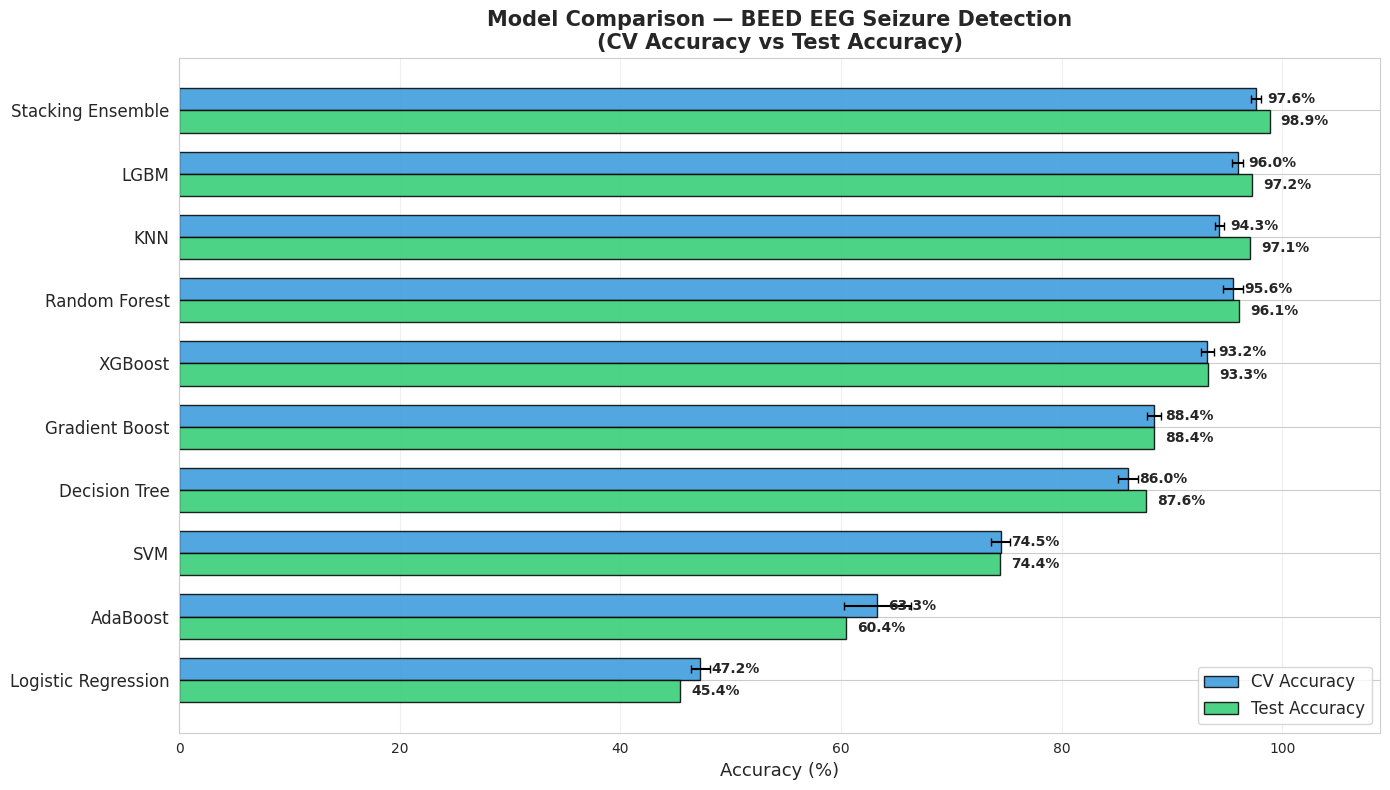

In [15]:
# ── Accuracy Bar Chart: CV vs Test ──
fig, ax = plt.subplots(figsize=(14, 8))

models = comparison_df['Model'].values
cv_accs = comparison_df['CV Accuracy (%)'].values
cv_stds = comparison_df['CV Std (%)'].values
test_accs = comparison_df['Test Accuracy (%)'].values

y_pos = np.arange(len(models))
bar_height = 0.35

# CV bars
bars_cv = ax.barh(y_pos - bar_height/2, cv_accs, bar_height, xerr=cv_stds,
                   label='CV Accuracy', color='#3498db', edgecolor='black', capsize=3, alpha=0.85)
# Test bars
bars_test = ax.barh(y_pos + bar_height/2, test_accs, bar_height,
                     label='Test Accuracy', color='#2ecc71', edgecolor='black', alpha=0.85)

# Labels on bars
for i, (cv, test) in enumerate(zip(cv_accs, test_accs)):
    ax.text(cv + 1.0, i - bar_height/2, f'{cv:.1f}%', va='center', fontsize=10, fontweight='bold')
    ax.text(test + 1.0, i + bar_height/2, f'{test:.1f}%', va='center', fontsize=10, fontweight='bold')

ax.set_yticks(y_pos)
ax.set_yticklabels(models, fontsize=12)
ax.set_xlabel('Accuracy (%)', fontsize=13)
ax.set_title('Model Comparison — BEED EEG Seizure Detection\n(CV Accuracy vs Test Accuracy)',
             fontsize=15, fontweight='bold')
ax.legend(fontsize=12, loc='lower right')
ax.invert_yaxis()
ax.grid(axis='x', alpha=0.3)
ax.set_xlim(0, max(max(cv_accs), max(test_accs)) + 10)

plt.tight_layout()
plt.show()

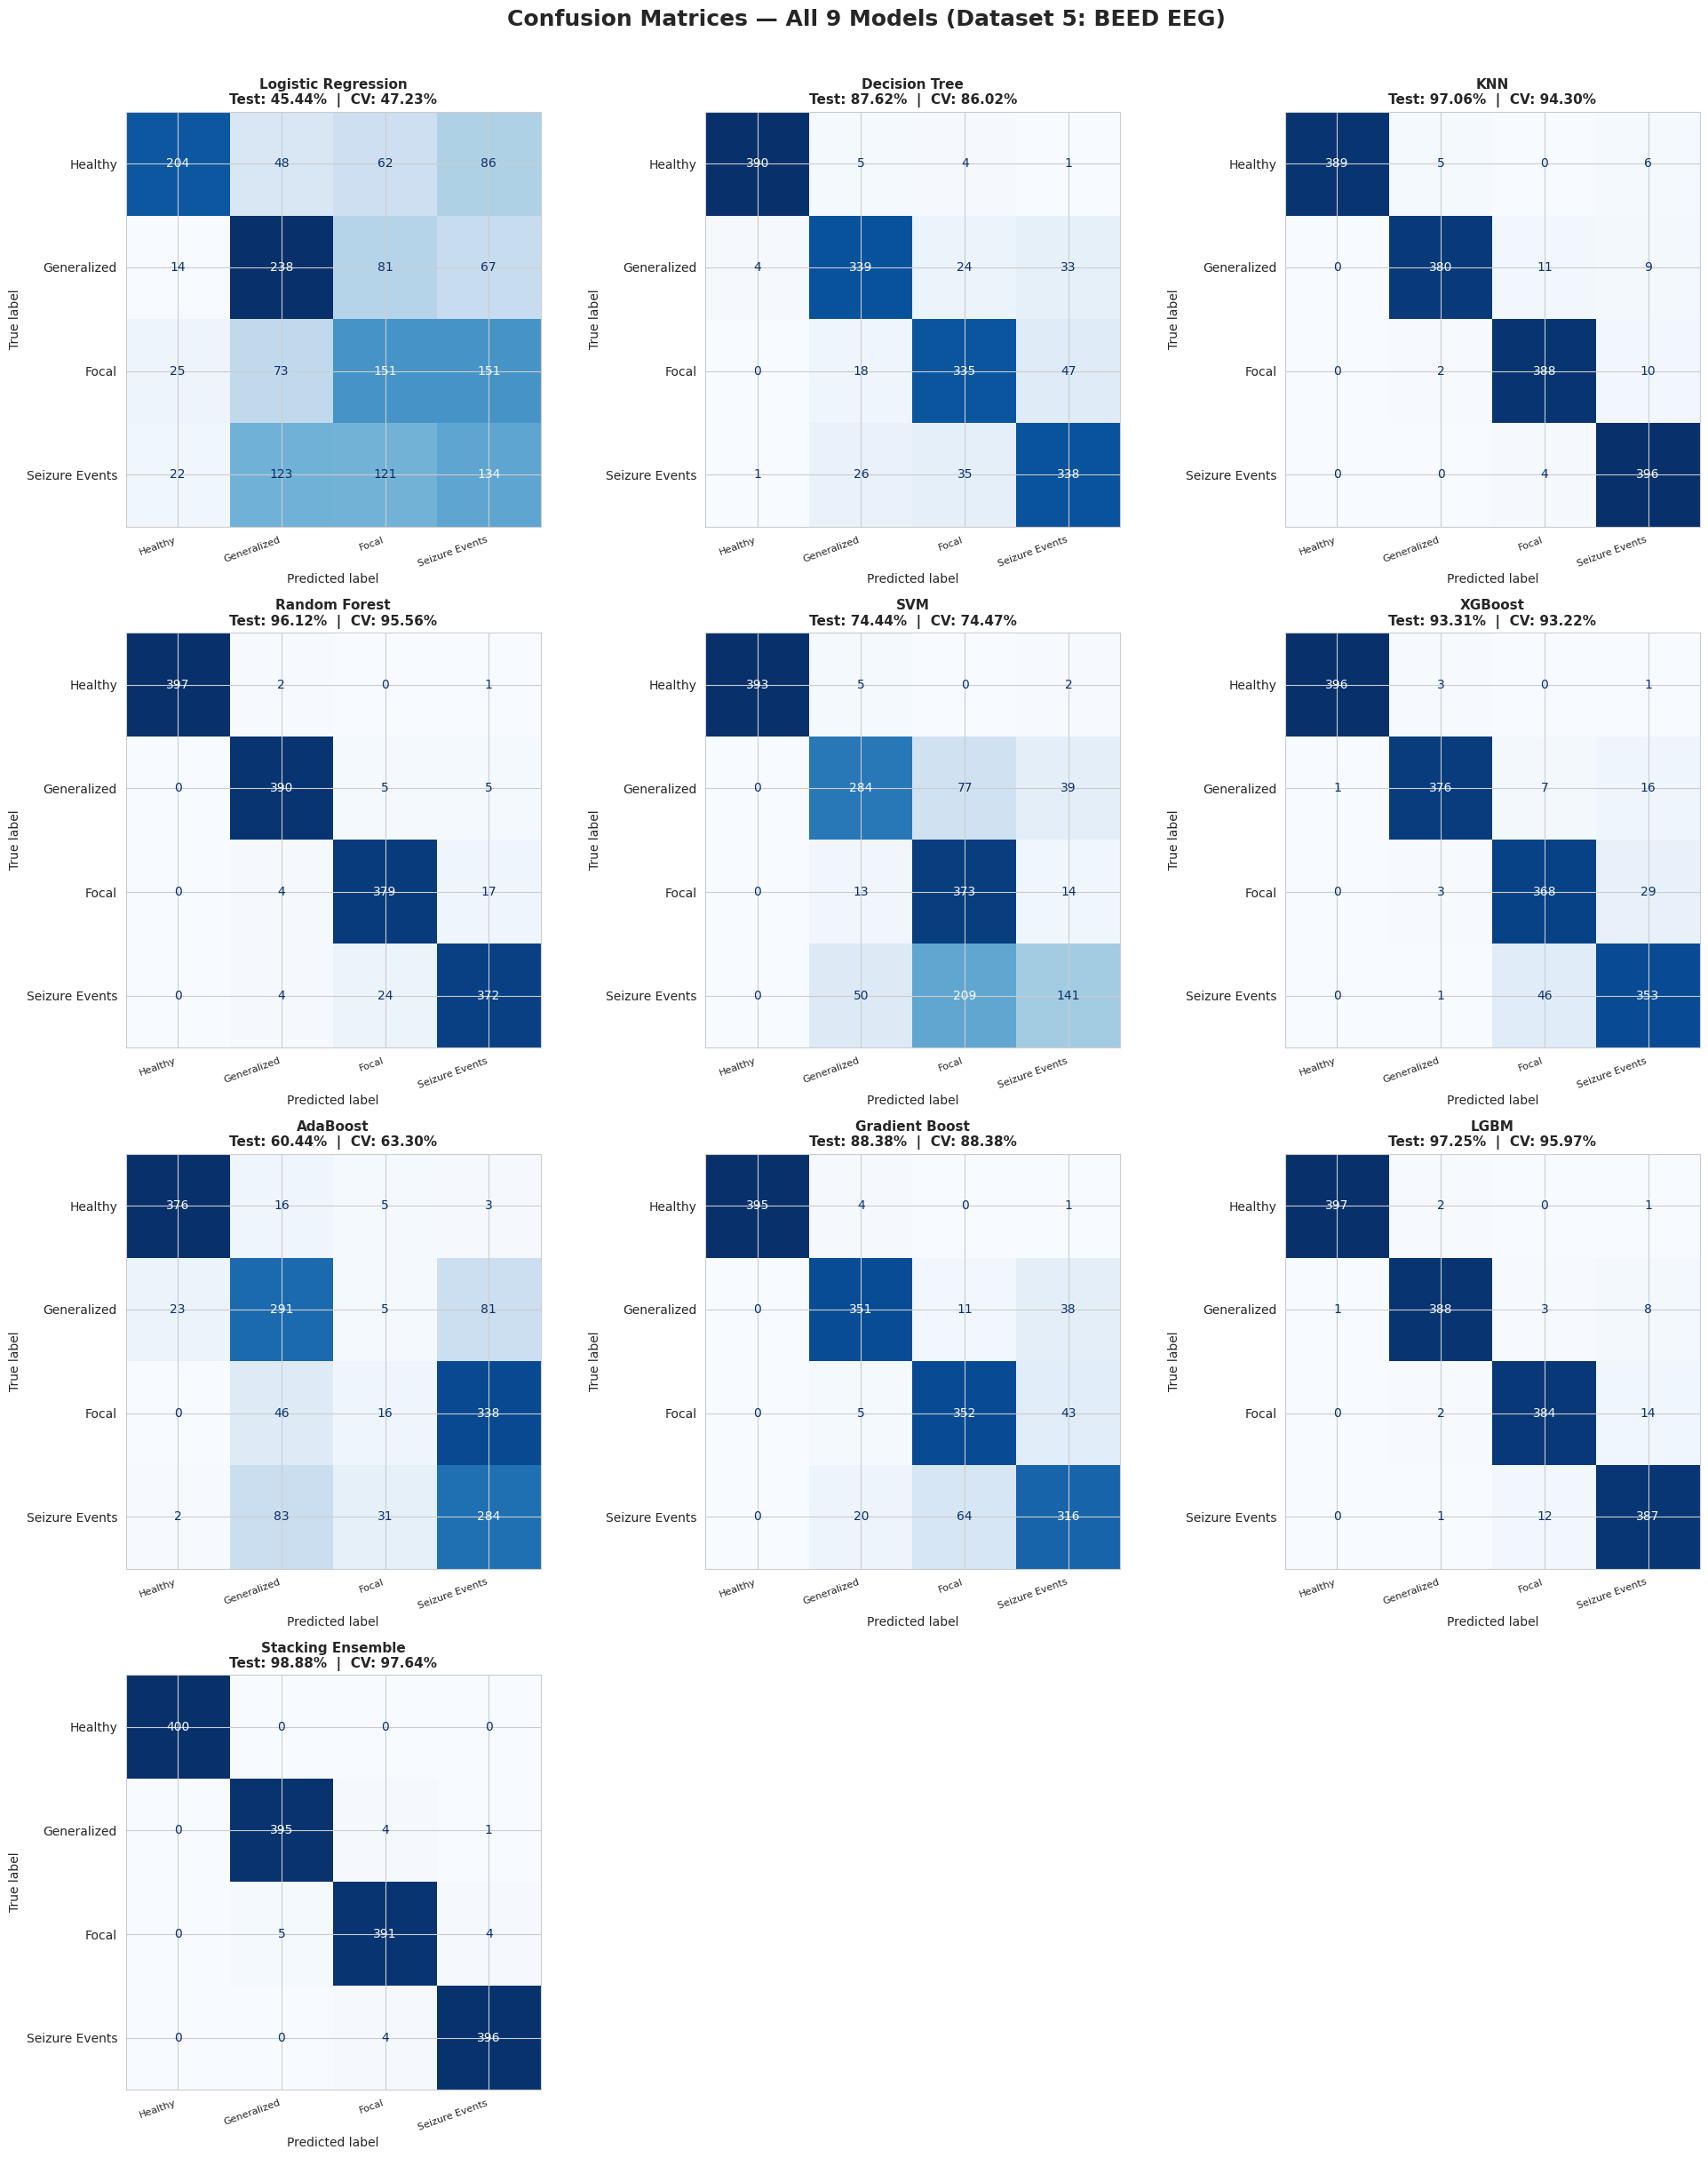

In [16]:
# ── All Confusion Matrices Side by Side ──
n_models = len(results)
n_cols = 3
n_rows = (n_models + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(20, 6 * n_rows))
axes = axes.ravel()

for idx, (name, data) in enumerate(results.items()):
    disp = ConfusionMatrixDisplay(
        confusion_matrix=data['confusion_matrix'],
        display_labels=CLASS_NAMES
    )
    disp.plot(ax=axes[idx], cmap='Blues', values_format='d', colorbar=False)
    axes[idx].set_title(f'{name}\nTest: {data["test_accuracy"]*100:.2f}%  |  CV: {data["cv_mean"]*100:.2f}%',
                         fontsize=11, fontweight='bold')
    axes[idx].set_xticklabels(CLASS_NAMES, rotation=20, ha='right', fontsize=8)

# Hide unused subplots
for idx in range(n_models, len(axes)):
    axes[idx].set_visible(False)

plt.suptitle('Confusion Matrices — All 9 Models (Dataset 5: BEED EEG)',
             fontsize=18, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()